# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') 
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print('Nulos users')
print(users.isnull().sum()) # Cantidad de valores nulos

print() # salto de linea

print('% nulos users')
print(users.isnull().mean()*100) # Proporción de valores nulos

Nulos users
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

% nulos users
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print('Nulos usage')
print(usage.isnull().sum())

print() # salto de linea

print('% Nulos usage')
print(usage.isnull().mean()*100)

Nulos usage
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

% Nulos usage
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- En **users** existen faltantes en las columnas:

     - *city* con un total de 469 nulos equivalente al **11.72%** al ser una columna categórica y no poder calcular alguna métrica para imputar se conservan como nulos.
     - *date_churn* tiene un total de 3534 nulos equivalente a **88.35%** para el análisis actual que queremos saber cómo es el uso de los usuarios segmentado por edades ésta columna no es indispensable por lo que se ignorará pero no se eliminará por si más adelante quisieran hacer un análisis como la retención de clientes, sólo se tendría que confirmar con el proveedor de datos que los nulos en esta columna corresponden a clientes que siguen activos con alguno de los planes de ConnectaTel.

 - En **usage** existen faltantes en las columnas:

     - *date* con un total de 50 nulos equivalente al **0.12%** al ser menos del 1% de faltantes se conservaran como nulos.
     - Las columnas **duratios** tiene 22076 equivalente al **55.19%** y **length** 17896 equivalente al **44.74%** de datos faltantes. Éstas dos columnas presentan una gran cantidad de faltantes sin embargo es posible que sean complementarias y que sus faltantes sean MAR (Missing At Random) ya que estos datos parecen depender del tipo (**type**) de uso, si es llamada o mensaje. De forma que si las fucionaramos en una sola columna realmente habrían 28 valores faltantes equivalente al **0.07%** y se mantendrían como nulos.


- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` tiene un total de 4,000 registros comenzando en con el *id* 10,000 y terminando en 13,999.
- La columna `age` tiene un total de 4,000 registros sin embargo s puede ver que tiene valores inválidos (**-999**) que será necesario imputarlos.

In [13]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas **id** y **user_id** contienen un total de 40,000 registros. *id* una columna indice, enumerando los registros y *user_id** es el número de identificación de cada cliente.
- Las columnas **duration** y **length** parecen tener un sesgo a la derecha ya que sus datos se concentran en valores pequeños y tienen outliers con valores altos, además de que sus valores mínimos son 0, lo cual pudiera indicar que los nulos en esas columnas se están tomando como números ya que no sería posible una llamada sin tiempo y un mensaje sin caracteres.

In [14]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']].describe()
print(columnas_user)

print() # salto de linea

users['city'].unique()

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595



array(['Medellín', '?', 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali'],
      dtype=object)

- La columna `city` se pueden observar los 469 registros faltantes, que Bogotá es la ciudad que más registros tiene con 808, también podemos ver que hay registro de "7" ciudades, sin embargo uno de esos valores podemos ver que es un sentinel (**?**) que será necesario remplazar.
- La columna `plan` se pueden observar completos los 4,000 registros con 2 valores únicos que corresponden al tipo de plan (*Básico* y *Premium*) siendo **Básico** el plan con mayor cantidad de registros (2,595).

In [15]:
# explorar columna categórica de usage
usage['type'].describe()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` contiene completos los 40,000 registros con 2 valores únicos correspondientes al tipo de uso que se le dan los usuarios al servicio *llamada* o *mensaje*.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

     Se encontraron valores inválisdos en las columnas de **age** (*-999*) y **city** (*?*).
- ¿Qué acción tomarías?

     En el caso de **age** sería bueno remplazar los sentinels con la mediana, para conservar los registros, poder utilizarlos en el análisis y evitar algún sesgo por algún outlier que pueda haber en la columna.

     Para **city** sería bueno remplazar los sentinels por nulos, para no perder la demás información de los registros, sin embargo no podemos inventar a qué ciudad corresponden dichos registros.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce') # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce') # completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

En `reg_date`, se puede ver que hay un error en los registros ya que aparece como año **2026** cuando en esta base de datos se supone se tiene información registrada *hasta* el año **2024**.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, podemos ver que sólo hay registros del año **2024** y registros en los que no hay fecha.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles?

     Sí, aparece el año **2026** y en esta base de datos sólo deberían haber datos hasta el año **2024**.


- ¿Qué harías con ellas?

     Para esos registros erroneos, recomendaría remplazarlos por nulos para evitar errores al realizar el análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].replace(-999, np.nan).median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city

users['city'] = users['city'].replace('?', np.nan)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [22]:
# Marcar fechas futuras como NA para reg_date

users.loc[users['reg_date'].dt.year == 2026, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.unique()


array([2022.,   nan, 2023., 2024.])

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()*100

type
call     0.000000
text    99.927576
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()*100

type
call    99.932991
text     0.000000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

- Con estos resultados podemos afirmar que los nulos en las columnas **duration** y **length** son tipo MAR, pues están directamente relacionadas con la columna **type**. Lo que nos dicen estos resultados es justo que duration (una llamada) no puede tener un longitud de caracteres y length (un mensaje) no puede tener una duración de tiempo.

- Lo mejor es conservar los nulos como nulos ya que no son datos perdidos sino que son valores ausentes por la propia lógica del negocio y no remplazarlos por 0 o alguna métrica como promedio o media.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage[['is_text', 'is_call']].groupby(usage['user_id']).sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call
0,10000,7,3
1,10001,5,10
2,10002,5,2


In [26]:
# renombro columnas de usage_agg
usage_agg = usage_agg.rename(columns={'is_text': 'cant_mensajes', 'is_call': 'cant_llamadas'})

# calculo los minutos de llamada por usuario
minutos_por_usuario = usage['duration'].groupby(usage['user_id']).sum().reset_index()

# renombro la columna duration
minutos_por_usuario = minutos_por_usuario.rename(columns={'duration': 'cant_minutos_llamada'})

# hago la unión de los dos datasets nuevos
usage_completo = pd.merge(usage_agg, minutos_por_usuario, on='user_id')

# compruebo el resultado
usage_completo.head(3) 


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(usage_completo, users, on='user_id')
user_profile.head(5)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)

Basico     0.648662
Premium    0.351338
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

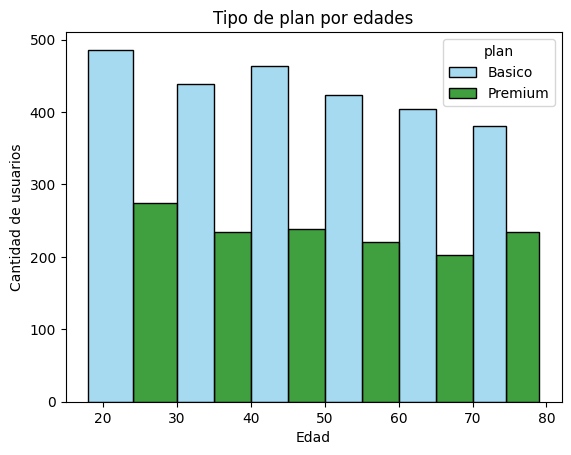

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', bins=[18, 30, 40, 50, 60, 70, 79], hue='plan', palette=['skyblue', 'green'], multiple='dodge')
plt.title('Tipo de plan por edades')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- 'Edad' tiene una distribución amplia desde jovenes hasta adultos mayores. Se puede observar que a pesar de tener una distribución mas o menos uniforme la mayoría de clientes se concentran en las personas más jóvenes entre los 18 a25 años y hay un pequeño declive conforme la edad va aumentando. Ahora en todos las edades es evidente que hay una mayor cantidad de clientes con un plan **básico** y el plan **premium** donde concentra más clientes es en el sector de los adultos jóvenes que va aproximadamente de 25 a 30 años.

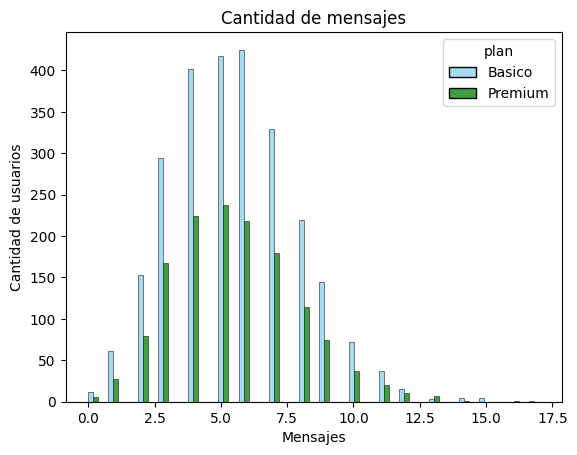

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], multiple='dodge')
plt.title('Cantidad de mensajes')
plt.xlabel('Mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La distribución en la cantidad de mensajes tine un ligero sesgo a la derecha, sin embargo la cantidad de mensajes se concentran aproximademente en 6 para el plan básico y 5 mensajes en el plan básico.

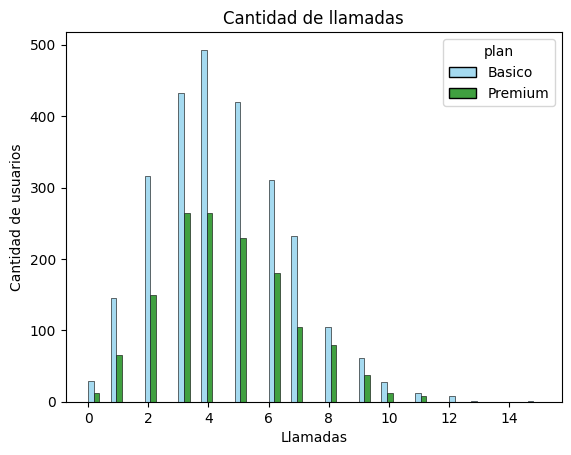

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], multiple='dodge')
plt.title('Cantidad de llamadas')
plt.xlabel('Llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La distribución en llamadas tiene un ligero sesgo a la derecha con algunos pocos usuarios con más de 14 llamadas y la mayoría se concentran en 4 llamadas para el plan básico y en el plan premium se concentran en 3 y 4 llamadas por igual.

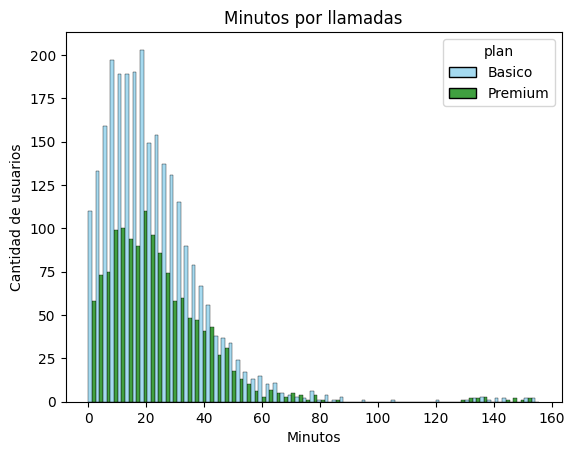

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], multiple='dodge')
plt.title('Minutos por llamadas')
plt.xlabel('Minutos')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- En los minutos por llamada es eviddente un sesgo a la derecha con algunos pocos con llamadas por arriba de los 140 minutos. Y realmente el usuario típico realiza llamadas de entre 10 y 20 minutos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

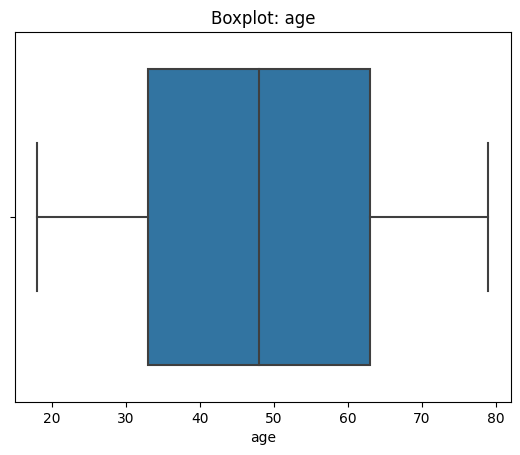

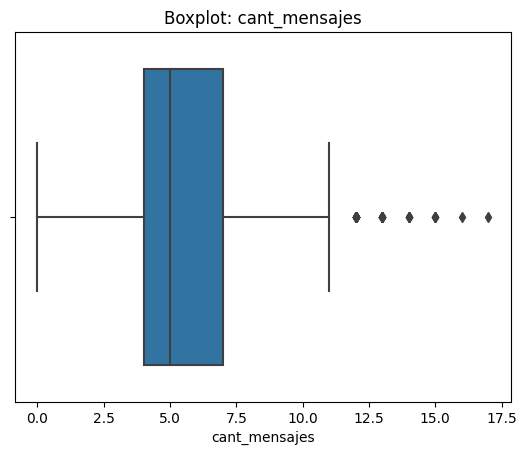

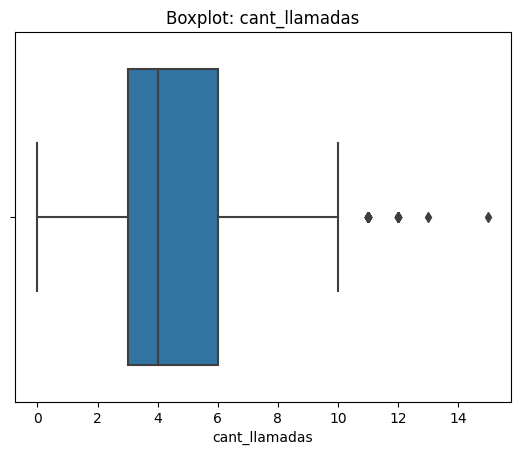

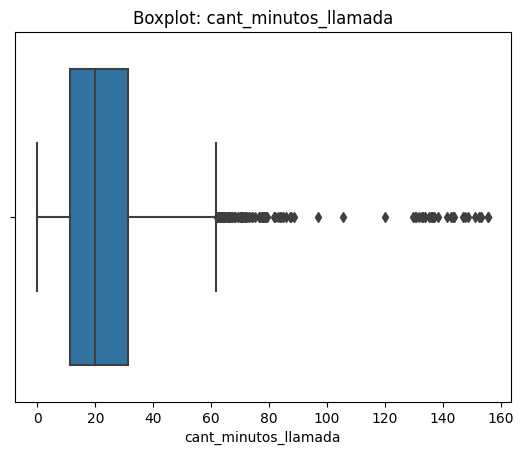

In [34]:
# Visualizando usando BoxPlot 


columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
                sns.boxplot(data = user_profile,x=col)
                plt.title(f'Boxplot: {col}')
                plt.show()



💡Insights: 
- Age: no presenta outliers, es un gropo de edades que van de poco menos de 20 años hasta casi 80 años con una mediana de poco menos de 50 años. (presenta o no outliers)
- cant_mensajes: sí presenta algunos outliers por encima del extremo superior, con una mediana de 5.
- cant_llamadas: presenta outliers por encima del extremo superior, con una mediana de 4.
- cant_minutos_llamada: presenta outliers por encima del extremo superior, los valores se concentran en valores pequeños y tiene una mediana de 20.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
            q1 = user_profile[col].quantile(0.25)
            q3 = user_profile[col].quantile(0.75)
            IQR = q3 - q1
            limite_superior = q3+1.5*IQR
            print('Primer cuartil: ', q1, 'Tercer quartil: ', q3, 'Rango intercuartílico: ', IQR, 'Límite superior: ', limite_superior)


Primer cuartil:  4.0 Tercer quartil:  7.0 Rango intercuartílico:  3.0 Límite superior:  11.5
Primer cuartil:  3.0 Tercer quartil:  6.0 Rango intercuartílico:  3.0 Límite superior:  10.5
Primer cuartil:  11.12 Tercer quartil:  31.415 Rango intercuartílico:  20.295 Límite superior:  61.8575


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener los outliers, pues tiene una desviación estánder baja que nos indica que tiene una baja variabilidad de los datos y lo podemos observar tambíén al ver poca diferencia entre el promedio y la mediana, además de que los outliers presentes son valores atípicos reales y de esta forma conservamos la integridad del dataset.

 
- cant_llamadas: mantener o no outliers, porqué? Por la proximidad entre el tercer cuartil y el límite superior podemos observar que hay una bada dispersión de datos indicando que los outliers son reales y decidimos conservarlos.


- cant_minutos_llamada: mantener o no outliers, porqué? Los outliers para la cantidad de minutos para llamadas podrían parecer un error, sin embargo el valor máximo es equivalente a dos horas y media, lo cual puede es un tiempo de llamada poco común pero posible, éstos usuarios simplemente tienen un alto consumo del servicio y podrían considerarse más adelante para generar algún otro tipo de plan de telecomunicaciones. Por lo que estos datos se consrevaran.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso


def clasificar_por_uso (row):

    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas']< 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_por_uso, axis=1)


In [38]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad

def clasificar_por_edad (row):

    if row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_por_edad, axis=1)


In [40]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso,Adulto Mayor
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

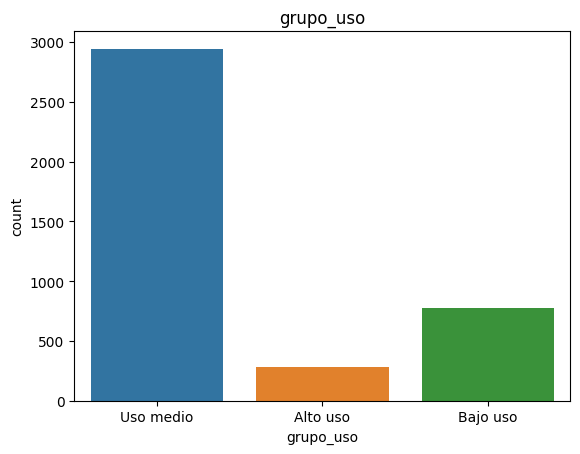

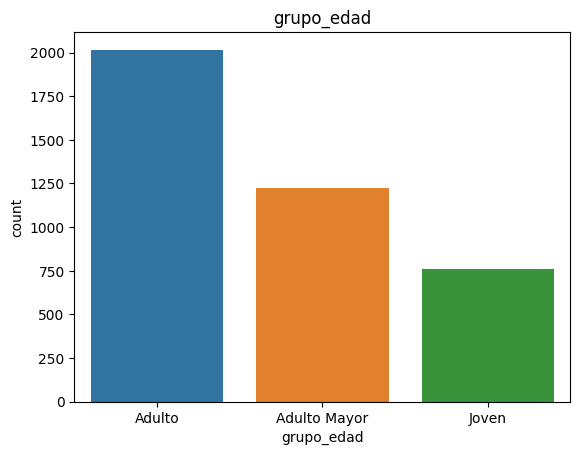

In [41]:
# Visualización de los segmentos por uso
columnas_por_segmentacion = ['grupo_uso', 'grupo_edad']

for col in columnas_por_segmentacion:
    sns.countplot(data=user_profile, x=col)
    plt.title(f'{col}')
    plt.show()

In [ ]:
# Visualización de los segmentos por edad



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

   - Los datos realmente presentaban pocos problemas.
   - El dataset de **users** presentaba nulos en las columnas *city* (11.72%) y *churn_date* (88.35%) y de éste último que podría alarmar ver un porcentaje tan alto de nulos, en esa culumna debería ser normal o bueno que sea así pues esa columna indica la fecha de abandono o cancelacion del plan de telecomunicaciones.
   - Otro de los problemas lo tenían las columnas de *age* con el sentinel (-999) y *city* con (?), los cuales se remplazaron con la mediana en el caso de las edades y por nulos en el caso de las ciudades.
   - El formato de las columnas de **fecha** convertirlas de formato general a formato fecha.
   - En el caso de la columna **reg_date** se identificó el registro de un año erroneo (2026), pues en esta base de datos sólo se recopilaron datos hasta el año 2024, por lo que se tuvieron que remplazar los años erroneos por nulos.
   - Por último en el dataset **usage** los faltandes en las columnas *date* con un 0.125% que son muy pocos nulos y las columnas de *duration* (55.19%) y *length* (44.74%) que presentaban una cantidad de nulos considerable, con esto solamento se confirmó que esos nulos fueran valores faltantes estructurales para poder comprender de dónde venían esos nulos y que significan.

 ---
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

    - Los clientes fueron segmentados por edad y por sus patrones de uso.
    - En la segmentación por **uso** se puede observar que la mayoría de los usuarios tienen un nivel de uso medio, algunos otros tienen un nivel bajo de uso de los servicios y sólo unos pocos usan mucho los servicios brindados por ConnectaTel.
    - La segmentación por **edad** nos muestra que la gran mayoría de los clientes forman parte de *adultos* entre los 30 y 59 años de edad, seguido de los adultos de 60 años y más y por último se encuentra el segmento de los jóvenes menores de 30 años.

---  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

    - El segmento más valioso parece ser el grupo de *adultos* porque forman la mayoría de los usuarios que tienen un plan con ConnectaTel, esto pudiera ser justificado porque este segmento de la población generalmente son quienes tienen una mayor estabilidad económica y un mayor poder adquisitivo.

 ---   
      
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

    - El outlier que más llama la atención se encuentra en el máximo de minutos por llamada, ya que hay usuarios que llegan a sostener llamadas por 2 horas y media. A pesar de que no son muchos usuarios quienes tienen este comportamiento sería bueno identificar si ese patrón de uso modifica los costos de operación de la empresa para así mismo hacer modificaciones en los planes de contratación.

    
---
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

    - Recomendaría analizar si los costos de operación de la empresa se ven alterados por los usuarios que hacen un uso extremo de los servicios y si es que sus costos aumentan, así mismo crear un nuevo plan de telecomunicaciones para usuarios con este patrón de uso.
    - Por otra parte se puede observar que la mayoría de los usuarios están dentro del plan *Básico*, buscando generar un mayor ingreso estable para la empresa, deberíamos identificar de los *Adultos* que son la mayoría y teniendo en cuenta que son un grupo generalmente mas estable y con mayor poder adquisitivo cántos están en el plan *Básico* y si son la mayoría, recomendaría hacer promociones para incentivar a este grupo a cambiarse al plan *Premium* considerando que este plan puede traer mayores ingresos a la empresa.
    - Por último un sector con gran potencial puede ser el de los *Jóvenes*, pues son un grupo minoritario, para aumentar la cantidad de clientes podría generarse algún nuevo plan como *"Teen Basic", y podría promocionarse el producto ofreciendo algunos GB de internet para redes sociales, que es algo que interesa a ese sector.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Encontrar nulos e identificar si son nulos reales o errores.
- Establecer que los datos tengan el formato adecuado.
- Si se encuentran inconsistencias en los datos decidir si mantenerlos como nulos, remplazarlos por alguna métrica/nulos ó eliminar registros.


🔍 **Segmentos por Edad**
- Pudimos ver que el rango va desde los 18 hasta los 79 concentrandose la mayoría entre los 30 y 59 años.
- Se segmentó en 3 grupos, menores de 30 años *Jóvenes*, mayores de 30 y menores de 60 *Adultos* y de 60 a 79 que es la mayor edad registrada *Adultos Mayores*. 


📊 **Segmentos por Nivel de Uso**
- En el uso se puede ver de forma general que la mayoría de los usuarios se concentran en un uso medio, con un sesgo a la derecha, es decir que existen algunos usuarios con un uso extremo de los servicios.
- Se segmentó en 3 grupos, *Bajo uso*, *Uso medio* y *Alto uso* y con un gráfico pudimos ver que precisamente el *Uso medio* es en el que se concentra la mayoría y que sólo unos pocos (los outliers) son los que se ven representados enel grupo de *Alto uso*.




💡 **Recomendaciones**
- Verificar si los costos de operación de la empresa aumentan con el uso exesivo de los servicios, como lo hacen algunos usuarios (outliers), para ajustar los planes de telecomunicaciones (quizá como un 'Premium Extendido').
- Incentivar a la mayoría de usuarios (el grupo de adultos) a través de promociones a adquirir el plan "Premium" con el objetivo de aumentar los ingresos ($) a la empresa.
- Crear un plan para el sector de "Jóvenes", que es un mercado con gran potencial ofreciendo GB para redes sociales que es son de gran interés para el sector con un plan por ejemplo "Teen Basic"

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`